# 08b — Is the optimiser working? Four tests

08 proposes trials. This notebook checks, with the data we have, whether it deserves trust.

| Test | Question | How |
|---|---|---|
| 1 | Is the code doing the maths it claims? | 08's own self-checks, re-run here |
| 2 | Are its "% chance" numbers honest? | hide one plant, predict its recipes, compare with what was measured |
| 3 | Does it pick better trials than simple rules? | replay: the optimiser may only pick recipes a hidden plant really made, and "learns" their real results |
| 4 | Are the cost and carbon numbers right? | re-price at the low / mid / high end of the survey, and with the old carbon placeholders; see if the answer changes |
| 5 | Do its predictions hold on NEW trials? | the prospective trial log written by 08 before casting, scored once results are filled in |

Every headline number carries a **95 % bootstrap interval**. A difference whose interval
crosses zero is reported as *not shown*.

**Nothing here changes 03 or 08.** The method is read straight out of
`03_Modelling_audited.ipynb` and `08_bayesian_optimiser_standalone.ipynb`, so the test
checks the real code, not a copy.

**The experimental unit is a recipe, not a batch.** Batches of the same recipe are grouped
exactly as 03 groups them (within 3 %), and a recipe counts once, however many cubes it has.

Run order: 00 → 03 → 03b → 08 → **08b**.

In [36]:
import json, io, contextlib, warnings, time
import numpy as np, pandas as pd, joblib
from scipy.stats import norm
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
T0 = time.time()

DATA_FILE      = "01_RAW_dataset.csv"
MODEL_NOTEBOOK = "03_Modelling_audited.ipynb"
OPT_NOTEBOOK   = "08_bayesian_optimiser_standalone.ipynb"

# ---- 08's engine, read from 08 itself (IS layer import + engine cell) ----
nb8 = json.load(open(OPT_NOTEBOOK))
c8 = ["".join(c["source"]) for c in nb8["cells"] if c["cell_type"] == "code"]
pick8 = lambda key: next(s for s in c8 if key in s)
E = {}
exec(pick8("from is_rules import"), E)
exec(pick8("class SDLOptimiser"), E)
_need = ["draw_joint", "select_batch", "offset_update", "rates_from_survey", "early_age_ratio",
         "STOP_REL_EHVI", "plant_results_from_log", "CARBON_FACTORS"]
_miss = [n for n in _need if n not in E]
if _miss:
    raise RuntimeError(f"{OPT_NOTEBOOK} in this folder is an OLDER version (missing {_miss}). "
                       "Replace it with the latest 08, run it, then run 08b.")

# ---- 03's method, read from 03 itself (as 03b does) ----
nb3 = json.load(open(MODEL_NOTEBOOK))
c3 = ["".join(c["source"]) for c in nb3["cells"] if c["cell_type"] == "code"]
pick3 = lambda key: next(s for s in c3 if key in s)
G = {}
_s = pick3("GROUP_TOL")
exec(_s.split("DATA_FILE")[0], G); exec(_s[_s.index("GROUP_TOL"):], G)
exec(pick3("TEXT_COLS").split("raw = pd.read_excel")[0], G)
FIT_FINAL = pick3("def fit_final"); FIT_FINAL = FIT_FINAL[:FIT_FINAL.index("strength_model    = fit_final")]

SM = joblib.load("strength_model.joblib"); WM = joblib.load("workability_model.joblib")
TRANSFER = json.load(open("plant_transfer.json"))
PPC_X = TRANSFER["ppc_model_x_pct"]
Z90 = E["Z90"]
print("08 engine and 03 method loaded")

08 engine and 03 method loaded


## 0. Data, grouped into recipes exactly as 03 does

03's cleaning, features and recipe grouping are run unchanged. PPC is fed to the models as
OPC + 35 % fly ash (as 08 does). The **as-batched** cement and fly ash are kept beside it,
because the IS gate and the cost must use what was really batched.

In [37]:
raw = pd.read_csv(DATA_FILE, low_memory=False)
df = raw[raw.record_id.notna()].reset_index(drop=True)
for c in df.columns:
    if c not in G["TEXT_COLS"]: df[c] = pd.to_numeric(df[c], errors="coerce")
for k in ["flyash", "ggbs", "other_scm"]: df[k] = df[k].fillna(0)                 # 03 section 1
df["binder"] = df[["cement", "flyash", "ggbs", "other_scm"]].sum(axis=1)
df["coarse"] = df[["agg_20mm", "agg_10mm", "agg_40mm", "agg_other"]].fillna(0).sum(axis=1)
df["fine"]   = df[["crushed_sand", "natural_sand"]].fillna(0).sum(axis=1)
df["mass"]   = df.binder + df.water_batched + df.coarse + df.fine + df.admixture1.fillna(0)
d = df[(df.coarse > 0) & (df.mass >= 2150) & (df.mass <= 2750)].copy()

d["cement_as_batched"], d["flyash_as_batched"] = d.cement, d.flyash
d["ctype_orig"] = d.cement_type.astype(str)
ppc = d.cement_type.astype(str).str.upper().str.contains("PPC")
d.loc[ppc, "flyash"] = d.loc[ppc, "flyash"] + d.loc[ppc, "cement"] * PPC_X / 100
d.loc[ppc, "cement"] = d.loc[ppc, "cement"] * (1 - PPC_X / 100)
d.loc[ppc, "cement_type"] = "OPC-equivalent"
G["df"] = d
with contextlib.redirect_stdout(io.StringIO()):
    exec(pick3("df['wb']"), G); exec(pick3("def recipe_groups"), G)
    exec(pick3("def fit_predict"), G); exec(FIT_FINAL, G)


def with_raw(D, target, extra_cols):
    """Attach as-batched quantities to 03's recipe table (same rows, same order)."""
    s = G["df"][G["df"][target].notna()].copy().reset_index(drop=True)
    s["grp"] = G["recipe_groups"](s); g = s.groupby("grp")
    x = g[extra_cols].mean().reset_index(drop=True).add_prefix("raw_")
    x["grade"] = g.grade.first().values; x["ctype"] = g.ctype_orig.first().values
    assert len(x) == len(D) and np.allclose(g[target].apply(lambda v: np.log(v).mean()).values, D.ly.values)
    return pd.concat([D.reset_index(drop=True), x], axis=1)


RAW_COLS = ["cement_as_batched", "flyash_as_batched", "ggbs", "water_batched", "admixture1",
            "crushed_sand", "natural_sand", "coarse", "target_slump"]
DS = with_raw(G["DS"], "fc", RAW_COLS)
DW = with_raw(G["DW"], "slump_mm", RAW_COLS)
PLANTS = sorted(DS.plant.unique())
print(f"{len(d)} batches -> {len(DS)} strength recipes, {len(DW)} slump recipes (the true number of "
      f"independent experimental conditions)\n")
print(pd.DataFrame({"strength recipes": DS.groupby("plant").size(),
                    "slump recipes": DW.groupby("plant").size(),
                    "batches": d.groupby("plant_lab_id").size()}).fillna(0).astype(int).to_string())

340 batches -> 71 strength recipes, 37 slump recipes (the true number of independent experimental conditions)

                               strength recipes  slump recipes  batches
Plant B                                          35             14       38
P1                                            2              2        3
Plant D                                    5              5      256
Plant A                15              6       18
Plant C                                         14             10       25


## 1. Test 1 — does the code do what it says?

08's own self-checks, re-run here: 03's printed example is reproduced exactly; the
Pareto and hypervolume routines match cases worked by hand; the plant update equals the
closed-form formula; a 7-day result counts less than a 28-day one; a recipe's correlation
with itself is 1. If any fails, this cell stops.

In [38]:
checks = pick8("engine self-checks passed")
with contextlib.redirect_stdout(io.StringIO()) as buf:
    exec(checks, E)
print([l for l in buf.getvalue().splitlines() if "self-checks" in l or "reproduced" in l])

['03 example reproduced: strength 44.3351 N/mm2, slump 152.89 mm  (features match training)', 'engine self-checks passed (Pareto, hypervolume, plant update, 7-day weight, joint correlation, survey rates)']


## 2. Test 2 — are the probabilities honest?

**Method (leave one plant out).** For each plant: refit 03's models **without** it
(same code, same settings), estimate the plant-to-plant spread τ from the **other** plants
only (as 03b does, Plant B excluded from τ — 03 section 8), then predict every recipe of the
hidden plant.

**Event checked.** "The recipe's measured mean strength reached the IS 10262 cl 4.2 target
mean for its own grade." The predicted chance uses the same spread 08 uses (model sd
widened by 03's conformal factor, plus τ²), with the replicate noise of an `n`-batch mean
added, because a measured mean carries it.

**Scores.**
* **Brier score** — mean of (chance − outcome)², lower is better. Compared with the
  "no-skill" score of always predicting the overall pass rate.
* **Reliability** — among recipes given ~70 %, about 70 % should pass.
* **90 % coverage** — the 90 % range should contain the measured value about 90 % of the time.

**Fully held out.** The conformal widening factor q90 is **recomputed** for every fit from a
10-fold cross-validation on the training plants only (03's own `fit_predict`, same rule as
03), so nothing from the hidden plant touches the prediction or its width.

In [39]:
_FITS = {}


def fit_without(D, target, drop):
    """03's fit_final() on every recipe EXCEPT the dropped plants, with q90 recomputed by
    03's own cross-validation rule on those training recipes only (nothing held-out leaks)."""
    key = (target, tuple(sorted(drop)))
    if key in _FITS:
        return _FITS[key]
    Dtr = D[~D.plant.isin(drop)].reset_index(drop=True)
    n = len(Dtr); folds = G["kfold"](n, min(10, n), np.random.default_rng(0))
    mu, sd = np.zeros(n), np.zeros(n)
    with contextlib.redirect_stdout(io.StringIO()):
        for te in folds:
            tr = np.setdiff1d(np.arange(n), te)
            mu[te], sd[te] = G["fit_predict"](Dtr, target, tr, te, seed=0)
        G["RESULTS"] = {target: {"mu": mu, "sd": sd}}          # what fit_final reads for q90
        m = G["fit_final"](Dtr, target, restarts=1)
    _FITS[key] = m
    return m


EXCL_TAU = ("Plant B",)      # 03 section 8: Plant B holds every mix below w/b 0.27 -> extrapolation


_Z = {}


def tau_without(D, target, P):
    """tau for hidden plant P from the OTHER plants only (nested leave-one-plant-out).
    Also keeps, per other plant, the standardised errors |y - mu| / sd of its recipes when it
    was hidden -- the raw material of a plant-level conformal quantile."""
    offs, zs = {}, []
    for q in PLANTS:
        if q == P or q.startswith(EXCL_TAU):
            continue
        te = D[D.plant == q].reset_index(drop=True)
        if len(te) < 2:
            continue
        m = fit_without(D, target, [q, P])
        pq = E["predict_batch"](m, te)
        offs[q] = float(np.mean(te.ly.values - pq["mu"]))
        zs += list(np.abs(te.ly.values - pq["mu"]) / np.sqrt(pq["sd_model"] ** 2 + m["noise"] ** 2 / te.n.values))
    _Z[(target, P)] = np.array(zs)
    v = list(offs.values())
    return (float(np.std(v, ddof=1)) if len(v) >= 2 else TRANSFER["tau"][target]["tau_log"]), offs


def calibrate(D, target, event):
    rows, taus = [], {}
    for P in PLANTS:
        te = D[D.plant == P].reset_index(drop=True)
        if len(te) == 0:
            continue
        m = fit_without(D, target, [P]); tau, _ = tau_without(D, target, P); taus[P] = tau
        p = E["predict_batch"](m, te); k = m["q90"] / Z90
        sd_obs = np.sqrt(p["sd_model"] ** 2 + m["noise"] ** 2 / te.n.values) * k
        for j in range(len(te)):
            ev = event(te.iloc[j])
            if ev is None:
                continue
            zz = np.sort(_Z[(target, P)]); nz = len(zz)
            q_plant = zz[min(int(np.ceil((nz + 1) * 0.90)) - 1, nz - 1)] if nz else m["q90"]
            base_sd = sd_obs[j] / k                               # before any widening
            for mode, s in (("without plant spread", sd_obs[j]),
                            ("with plant spread (08)", np.sqrt(sd_obs[j] ** 2 + tau ** 2)),
                            ("plant-level conformal (no tau)", base_sd * q_plant / Z90)):
                rows.append({"plant": P, "mode": mode, "P": ev(p["mu"][j], s), "y": ev.hit,
                             "in90": int(abs(te.ly[j] - p["mu"][j]) <= Z90 * s)})
    return pd.DataFrame(rows), taus


class Above:
    """Event: measured mean >= threshold (log)."""
    def __init__(self, thr, ly): self.t, self.hit = np.log(thr), int(ly >= np.log(thr))
    def __call__(self, mu, s): return 1 - norm.cdf((self.t - mu) / s)


class InBand:
    """Event: measured slump inside the IS 4926 cl 6.2.1 band."""
    def __init__(self, lo, hi, ly):
        self.lo, self.hi, self.hit = np.log(lo), np.log(hi), int(np.log(lo) <= ly <= np.log(hi))
    def __call__(self, mu, s): return norm.cdf((self.hi - mu) / s) - norm.cdf((self.lo - mu) / s)


def strength_event(r):
    try:
        tm = E["target_mean_strength"](str(r.grade))["target_mean"]    # IS 10262 cl 4.2
    except Exception:
        return None
    return Above(tm, r.ly)


def slump_event(r):
    ts = r.raw_target_slump
    if not np.isfinite(ts) or not E["slump_reading_valid"](ts)["valid"]:    # IS 1199 Pt 2
        return None
    b = E["slump_acceptance_band"](ts)                                        # IS 4926 cl 6.2.1
    return InBand(b["low"], b["high"], r.ly)


def skill(g):
    base = np.mean((g.y.mean() - g.y) ** 2)
    return 1 - np.mean((g.P - g.y) ** 2) / base if base > 0 else np.nan


def boot(g, f, n=4000, seed=0):
    """95 % percentile bootstrap over recipes (the experimental unit)."""
    r = np.random.default_rng(seed); v = []
    for _ in range(n):
        x = f(g.iloc[r.integers(0, len(g), len(g))])
        if np.isfinite(x):
            v.append(x)
    return np.percentile(v, [2.5, 97.5])


def summary(Cal):
    out = []
    for mode, g in Cal.groupby("mode", sort=False):
        sk, cv = boot(g, skill), boot(g, lambda h: h.in90.mean())
        out.append({"": mode, "recipes": len(g), "mean predicted chance": g.P.mean(),
                    "observed pass rate": g.y.mean(), "Brier": np.mean((g.P - g.y) ** 2),
                    "no-skill Brier": np.mean((g.y.mean() - g.y) ** 2),
                    "skill": skill(g), "skill 95% CI": f"[{sk[0]:.2f}, {sk[1]:.2f}]",
                    "90% range coverage": g.in90.mean(), "coverage 95% CI": f"[{cv[0]:.2f}, {cv[1]:.2f}]"})
    return pd.DataFrame(out).set_index("")


CAL_S, TAU_S = calibrate(DS, "fc", strength_event)
print("STRENGTH: tau used for each hidden plant (from the other plants only):",
      {k[:12]: round(v, 3) for k, v in TAU_S.items()})
print(summary(CAL_S).round(3).T.to_string())
g_ = CAL_S[CAL_S["mode"] == "with plant spread (08)"]
print("\nsensitivity -- skill with one plant's recipes removed from the score:")
print("  " + " | ".join(f"without {p[:10]}: {skill(g_[g_.plant != p]):+.2f}" for p in g_.plant.unique()))

STRENGTH: tau used for each hidden plant (from the other plants only): {'Plant B': 0.145, 'P1': 0.043, 'Plant D': 0.068, 'Plant A': 0.121, 'Plant C': 0.044}
                      without plant spread with plant spread (08) plant-level conformal (no tau)
recipes                                 71                     71                             71
mean predicted chance                0.682                  0.654                          0.677
observed pass rate                   0.746                  0.746                          0.746
Brier                                 0.16                  0.164                          0.169
no-skill Brier                       0.189                  0.189                          0.189
skill                                0.154                  0.135                          0.108
skill 95% CI                 [-0.19, 0.38]          [-0.21, 0.34]                  [-0.26, 0.35]
90% range coverage                   0.915                  0.972  

reliability (strength, with plant spread):
                recipes  mean_chance  passed
bin                                         
(-0.001, 0.25]        5         0.23    0.20
(0.25, 0.5]          15         0.41    0.53
(0.5, 0.75]          23         0.66    0.87
(0.75, 0.95]         26         0.85    0.85
(0.95, 1.0]           2         0.99    1.00

by hidden plant:
                               recipes  mean_chance  passed  coverage90
plant                                                                  
Plant B                                 35         0.58    0.74        1.00
P1                                   2         0.87    0.00        0.50
Plant D                           5         0.30    0.00        1.00
Plant A       15         0.79    1.00        1.00
Plant C                                14         0.78    0.86        0.93


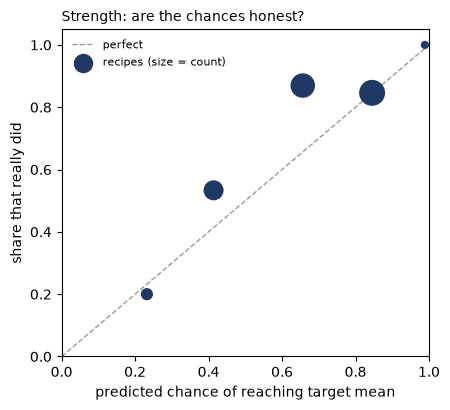

In [40]:
g = CAL_S[CAL_S["mode"] == "with plant spread (08)"].copy()
g["bin"] = pd.cut(g.P, [0, .25, .5, .75, .95, 1.0001], include_lowest=True)
rel = g.groupby("bin", observed=True).agg(recipes=("y", "size"), mean_chance=("P", "mean"), passed=("y", "mean"))
print("reliability (strength, with plant spread):"); print(rel.round(2).to_string())
print("\nby hidden plant:")
print(g.groupby("plant").agg(recipes=("y", "size"), mean_chance=("P", "mean"), passed=("y", "mean"),
                             coverage90=("in90", "mean")).round(2).to_string())

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color="#9A9A9A", lw=1, ls="--", label="perfect")
ax.scatter(rel.mean_chance, rel.passed, s=rel.recipes * 12, color="#1F3864", zorder=3, label="recipes (size = count)")
ax.set_xlabel("predicted chance of reaching target mean"); ax.set_ylabel("share that really did")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.05); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Strength: are the chances honest?", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

In [29]:
CAL_W, TAU_W = calibrate(DW, "slump_mm", slump_event)
print("SLUMP: tau for each hidden plant:", {k[:12]: round(v, 3) for k, v in TAU_W.items()})
print(summary(CAL_W).round(3).T.to_string())
print("\nskill < 0 means the model's slump chances are WORSE than always guessing the average"
      " pass rate at a plant it has not seen -- the reason 08 does not filter on slump until a"
      " slump is measured there (IS 10262 cl 5.8).")

SLUMP: tau for each hidden plant: {'Plant B': 0.493, 'P1': 0.475, 'Plant D': 0.351, 'Plant A': 0.44, 'Plant C': 0.364}
                      without plant spread with plant spread (08) plant-level conformal (no tau)
recipes                                 23                     23                             23
mean predicted chance                0.219                  0.207                          0.187
observed pass rate                   0.435                  0.435                          0.435
Brier                                0.361                  0.314                          0.313
no-skill Brier                       0.246                  0.246                          0.246
skill                               -0.468                 -0.279                         -0.274
skill 95% CI                [-1.18, -0.14]         [-0.91, -0.06]                 [-0.94, -0.04]
90% range coverage                   0.739                  0.957                            1.0
coverage

## 3. Test 3 — does it pick better trials than simple rules? (replay)

**Set-up.** A plant is hidden. The models are refitted without it, and τ comes from the
other plants. The optimiser acts as if it were at that plant for the first time: it may
only choose among recipes that plant **really made** and that pass the IS gate for the
requirement; when it "casts" one, it learns that recipe's **real measured** strength, and
the plant offset is updated exactly as 08 does. This is the pool-based benchmark of
Liang et al. (2021, *npj Comput. Mater.*) and Rohr et al. (2020, *Chem. Sci.*).

**Goal of each task.** Find the recipes that met the IS 10262 target mean at the lowest
cost and carbon (the measured Pareto front), with few trials and few failed trials.
Tasks = hidden plant × requirement (grade/exposure). Batches of 4, as in 08.

**Strategies compared.**

| strategy | what it does |
|---|---|
| 08 now: safe-first, then 1% stop | expected hypervolume gain weighted by the joint chance of passing; only mixes with chance ≥ 0.475 while any exist, then all mixes; stops when the best expected gain is < 1 % of what measured mixes already achieve (Jones et al. 1998 rule) |
| 08 before: cut-off 0.475 | mixes below a 0.475 chance are never tried; stops when none is left |
| pure constrained EHVI, 1% stop | no tier at all: every mix, weighted by its chance (Gardner et al. 2014 style) |
| independent draws, 1% stop | as pure EHVI, but pass/fail of batch members drawn independently |
| greedy cheapest-safe | cheapest recipe with chance ≥ 0.95, else the safest |
| random | 300 random orders (the baseline) |

All rules were written down **before** this test was run; none has a tuned number. The
default in 08 was then chosen by the project's own order of objectives — fewer wasted trials
first, then finding the cheapest passing mix. Because that choice was made on these 12 tasks,
Test 5 (new trials) must confirm it.

**Scores, at equal budgets.** Share of the true front's hypervolume found after 4 and 8
trials; whether the cheapest recipe that passed was found by trial 8 and by the time the
rule stopped; failed trials (wasted batches) within the first 4 and 8 trials; trials used.

**Limits** — read before the numbers. Only plants with enough recipes that pass the IS gate
can be hidden. Pools are small (a plant makes ~10–15 designs), so one task can swing a
lot. The optimiser can only choose what the plant already made: this tests *choosing*,
not *discovering*. Recipes with no recorded cement type are left out (fail-safe).

In [30]:
MAT = {ct: E["Materials"](cement_type=ct) for ct in ("OPC", "PPC")}


def ctype(u):
    u = str(u).upper()
    return "PPC" if "PPC" in u else ("OPC" if "OPC" in u else None)


def priced(r, ct):
    mix = {"cement_kg_m3": r.raw_cement_as_batched, "flyash_kg_m3": r.raw_flyash_as_batched,
           "ggbs_kg_m3": r.raw_ggbs, "crushed_sand_kg_m3": np.nan_to_num(r.raw_crushed_sand),
           "natural_sand_kg_m3": np.nan_to_num(r.raw_natural_sand), "coarse_agg_kg_m3": r.raw_coarse,
           "admixture_kg_m3": np.nan_to_num(r.raw_admixture1), "water_kg_m3": r.raw_water_batched}
    return E["cost_carbon"](mix, MAT[ct])


def make_pool(P, exposure, grade):
    """Recipes plant P really made that the IS gate DECIDES as passing for this requirement."""
    rows = []
    for _, r in DS[DS.plant == P].iterrows():
        ct = ctype(r.ctype)
        if ct is None:
            continue                                                   # fail-safe
        g = E["compliance_gate"](
            cement_kg_m3=r.raw_cement_as_batched, fly_ash_kg_m3=r.raw_flyash_as_batched,
            ggbs_kg_m3=r.raw_ggbs, other_scm_kg_m3=0.0,
            free_water_kg_m3=r.raw_water_batched + np.nan_to_num(r.raw_admixture1),
            grade=grade, exposure=exposure, use="rcc", msa_mm=20, cement_type=ct, volume_closure_m3=1.0)
        if not g["decided"]:
            continue
        c, co = priced(r, ct)
        rows.append({**r.to_dict(), "cost": c, "carbon": co})
    return pd.DataFrame(rows).reset_index(drop=True)


Q = 4                    # batch of 4, as 08
OLD_CUT = 0.95 * 0.5     # the previous 08 rule: skip P(feasible) < 0.475, stop when none left
STOP = E["STOP_REL_EHVI"]  # the current 08 rule: stop when best E[gain] < 1 % of measured HV

# name -> (joint draws?, hard cut-off, relative stop, safe-first)
RULES = {                                        # all fixed BEFORE the test was run
    "08 now: safe-first, then 1% stop":    (True,  OLD_CUT, STOP, True),
    "08 before: cut-off 0.475":            (True,  OLD_CUT, 0.0,  False),
    "pure constrained EHVI, 1% stop":      (True,  0.0,     STOP, False),
    "independent draws, 1% stop":          (False, 0.0,     STOP, False),
    "greedy cheapest-safe":                None,
}


def replay(strategy, pool, m, tau, tlog, ref, rng, n_mc=3000):
    """One trajectory. Returns the order in which recipes were 'cast'."""
    left, obs = list(range(len(pool))), []
    pts, ok_true = pool[["cost", "carbon"]].values, pool.ly.values >= tlog
    while left:
        if obs:                                                          # 08's plant update
            po = E["predict_batch"](m, pool.iloc[obs])
            off = E["offset_update"](pool.ly.values[obs] - po["mu"], m["noise"] ** 2 / pool.n.values[obs], tau)
        else:
            off = {"offset": 0.0, "var": tau ** 2}
        cand = pool.iloc[left].reset_index(drop=True)
        if strategy == "random":
            k = list(rng.permutation(len(left))[:Q])
        else:
            p = E["predict_batch"](m, cand); kq = m["q90"] / Z90
            pf = 1 - norm.cdf((tlog - p["mu"] - off["offset"]) / np.sqrt((p["sd_model"] * kq) ** 2 + off["var"]))
            won = [o for o in obs if ok_true[o]]
            F0 = pts[won] if won else np.empty((0, 2))
            if strategy == "greedy cheapest-safe":
                ok = np.where(pf >= OLD_CUT)[0]
                if len(ok) == 0:
                    break
                safe = sorted([i for i in ok if pf[i] >= 0.95], key=lambda i: pts[left[i], 0])
                k = (safe + sorted([i for i in ok if i not in safe], key=lambda i: -pf[i]))[:Q]
            else:
                joint, cut, rel, safe_first = RULES[strategy]
                ok = np.where(pf > cut)[0] if cut > 0 else np.where(pf > 0)[0]
                if safe_first and len(ok) == 0:                          # safe options used up
                    ok, rel = np.where(pf > 0)[0], STOP
                if len(ok) == 0:
                    break
                sub = cand.iloc[ok].reset_index(drop=True)
                S = (E["draw_joint"](m, sub, off, n_mc, rng, with_noise=False) >= tlog) if joint \
                    else (rng.random((n_mc, len(ok))) < pf[ok])
                min_gain = rel * E["hv2d"](F0, ref) if len(F0) else 0.0
                pk, _ = E["select_batch"](pts[[left[i] for i in ok]], S, F0, ref, Q, min_gain=min_gain)
                if not pk:
                    break
                k = [ok[i] for i in pk]
        chosen = [left[i] for i in k]
        obs += chosen
        left = [l for l in left if l not in chosen]
    return obs


def score(order, pool, tlog, ref):
    pts, ok = pool[["cost", "carbon"]].values, pool.ly.values >= tlog
    true_hv = E["hv2d"](pts[ok], ref)
    hv = lambda t: E["hv2d"](pts[[o for o in order[:t] if ok[o]]], ref) / true_hv if any(ok[o] for o in order[:t]) else 0.0
    best = int(np.argmin(np.where(ok, pts[:, 0], np.inf)))
    fails = lambda t: int(sum(1 for o in order[:t] if not ok[o]))
    return {"HV @4": hv(4), "HV @8": hv(8), "HV at stop": hv(len(order)),
            "cheapest pass found @8": best in order[:8], "cheapest pass found at stop": best in order,
            "failed @4": fails(4), "failed @8": fails(8), "trials used": len(order), "failed at stop": fails(len(order))}

In [31]:
TASKS = [("moderate", "M25"), ("severe", "M30"), ("severe", "M35"),
         ("severe", "M40"), ("severe", "M45"), ("severe", "M50")]
STRATS = list(RULES)
rows = []
for P in PLANTS:
    pools = {t: make_pool(P, *t) for t in TASKS}
    if max(len(v) for v in pools.values()) < 6:
        continue                                             # too few gate-passing recipes to hide this plant
    m = fit_without(DS, "fc", [P]); tau = TAU_S[P]
    for (expo, grade), pool in pools.items():
        tlog = np.log(E["target_mean_strength"](grade)["target_mean"])
        n_ok = int((pool.ly >= tlog).sum()) if len(pool) else 0
        if len(pool) < 6 or n_ok == 0:
            continue
        a = pool[["cost", "carbon"]].values; ref = a.max(0) + 0.1 * (a.max(0) - a.min(0) + 1e-9)
        base = {"plant": P[:14], "task": f"{grade} {expo}", "pool": len(pool), "passed in pool": n_ok}
        for st in STRATS:
            rows.append({**base, "strategy": st,
                         **score(replay(st, pool, m, tau, tlog, ref, np.random.default_rng(0)), pool, tlog, ref)})
        R = [score(replay("random", pool, m, tau, tlog, ref, np.random.default_rng(s_)), pool, tlog, ref)
             for s_ in range(300)]
        rows.append({**base, "strategy": "random (mean of 300)",
                     **{k: float(np.mean([r[k] for r in R])) for k in R[0]}})
BENCH = pd.DataFrame(rows)
print(f"{BENCH[['plant','task']].drop_duplicates().shape[0]} tasks on {BENCH.plant.nunique()} hidden plant(s)\n")
print(BENCH.round(2).to_string(index=False))

12 tasks on 2 hidden plant(s)

         plant         task  pool  passed in pool                         strategy  HV @4  HV @8  HV at stop cheapest pass found @8 cheapest pass found at stop  failed @4  failed @8  trials used  failed at stop
Plant A M25 moderate    11              11 08 now: safe-first, then 1% stop   1.00   1.00        1.00                   True                        True       0.00       0.00          4.0             0.0
Plant A M25 moderate    11              11         08 before: cut-off 0.475   1.00   1.00        1.00                   True                        True       0.00       0.00          4.0             0.0
Plant A M25 moderate    11              11   pure constrained EHVI, 1% stop   1.00   1.00        1.00                   True                        True       0.00       0.00          4.0             0.0
Plant A M25 moderate    11              11       independent draws, 1% stop   1.00   1.00        1.00                   True                      

mean over tasks (HV = share of the true cost-carbon front found; 1.0 = all of it)

                                  HV @4  HV @8  HV at stop cheapest pass found @8 cheapest pass found at stop  failed @4  failed @8  trials used
strategy                                                                                                                                        
08 now: safe-first, then 1% stop   0.85   0.93        0.93               0.833333                    0.833333       0.67       0.92         4.17
08 before: cut-off 0.475           0.85   0.85        0.85                   0.75                        0.75       0.67       0.67         3.58
pure constrained EHVI, 1% stop     0.68   1.00        1.00                    1.0                         1.0       2.42       3.25         6.00
independent draws, 1% stop         0.66   1.00        1.00                    1.0                         1.0       2.58       3.42         5.92
greedy cheapest-safe               0.72   0.83 

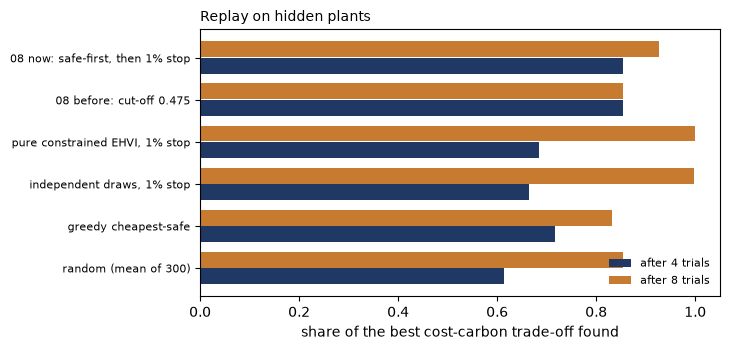

In [32]:
order = STRATS + ["random (mean of 300)"]
cols = ["HV @4", "HV @8", "HV at stop", "cheapest pass found @8", "cheapest pass found at stop",
        "failed @4", "failed @8", "trials used"]
S_ = BENCH.groupby("strategy")[cols].mean().loc[order]
print("mean over tasks (HV = share of the true cost-carbon front found; 1.0 = all of it)\n")
print(S_.round(2).to_string())


def paired(col, a, b="random (mean of 300)", n=4000, seed=0):
    """Mean difference a - b over tasks, 95 % bootstrap interval (tasks resampled)."""
    pv = BENCH.pivot_table(index=["plant", "task"], columns="strategy", values=col)
    d = (pv[a] - pv[b]).values.astype(float); r = np.random.default_rng(seed)
    bs = [d[r.integers(0, len(d), len(d))].mean() for _ in range(n)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return f"{d.mean():+.2f} [{lo:+.2f}, {hi:+.2f}]" + ("" if lo > 0 or hi < 0 else "  (not shown)")


print("\nvs random at the SAME budget -- mean difference [95% CI]:")
print(pd.DataFrame({c: {st: paired(c, st) for st in STRATS} for c in ["HV @4", "HV @8", "failed @4", "failed @8"]}).to_string())
print("\n08 now against the alternatives -- mean difference [95% CI]:")
print(pd.DataFrame({f"08 now - {o}": {c: paired(c, STRATS[0], o) for c in
                    ["HV @4", "HV @8", "cheapest pass found at stop", "failed @4", "failed @8", "trials used"]}
                    for o in STRATS[1:3]}).to_string())
print("\ncaution: tasks from the same plant are not independent, so these intervals are optimistic.")

fig, ax = plt.subplots(figsize=(7.4, 3.6))
y = np.arange(len(order))
ax.barh(y + 0.2, S_["HV @4"], height=0.38, color="#1F3864", label="after 4 trials")
ax.barh(y - 0.2, S_["HV @8"], height=0.38, color="#C77B30", label="after 8 trials")
ax.set_yticks(y); ax.set_yticklabels(order, fontsize=8); ax.invert_yaxis(); ax.set_xlim(0, 1.05)
ax.set_xlabel("share of the best cost-carbon trade-off found"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Replay on hidden plants", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 4. Test 4 — are the cost and carbon numbers right?

The **form** of both models is standard: each is a sum of (kg of each ingredient per m³) ×
(rate or carbon factor per kg), cradle-to-gate for carbon. That form is exact arithmetic,
which is why 08 does not model it. The **numbers** are the question.

**Cost.** 08 uses the project's market survey (Sep 2026) [PC]: each range's middle, less
the bulk discount, plus delivery. PPC and coarse aggregate are not in the survey; they are
**derived** from surveyed OPC and M-sand by a price ratio from one published listing
(infralens.in, Mumbai, 12 Aug 2026 [S]) [EI]. The test re-prices 08's whole search at the
**low** and **high** end of every range and checks whether the recommended recipe changes.

**Carbon.** 08 now uses published factors [S]: India Construction Materials Database
(IFC/EDGE 2017, Table 14) for cements, fly ash and aggregates; EFCA (2002) for
superplasticiser. GGBS and water remain unverified [U]. The test re-computes carbon with the
**old placeholders** to see whether the choice depends on them.

In [33]:
# 08's own search, run exactly as 08 runs it (sections 1-3), then re-priced.
for key in ("import sklearn, json", 'req = Requirement(grade="M30"', "DOMAIN = data_domain(",
            "X0, seed_mix = opt.seed(", "history = opt.evaluate(X0)"):
    with contextlib.redirect_stdout(io.StringIO()):
        exec(pick8(key), E)
H, mat0 = E["history"], E["mat"]

CO2_OLD = {"OPC": 900, "PPC": 639, "flyash": 30, "ggbs": 80, "crushed_sand": 6,
           "natural_sand": 4, "coarse": 5, "admixture": 1500, "water": 0.3}
SCEN = {
    "08 now (survey mid)": ({}, {}),
    "survey low end": (E["rates_from_survey"]("low"), {}),
    "survey high end": (E["rates_from_survey"]("high"), {}),
    "no bulk discount, no delivery": (E["rates_from_survey"]("mid", bulk=False, delivered=False), {}),
    "old carbon placeholders": ({}, CO2_OLD),
}
F = H[H.feasible].copy()
out, picks = [], {}
for name, (dc, dco) in SCEN.items():
    mt = E["Materials"](**{**mat0.__dict__, "cost": {**mat0.cost, **dc}, "carbon": {**mat0.carbon, **dco}})
    cc = np.array([E["cost_carbon"](r, mt) for r in F.to_dict("records")])
    F[f"cost|{name}"], F[f"co2|{name}"] = cc[:, 0], cc[:, 1]
    V = cc; front = E["pareto_points"](V)
    i_cost, i_co2 = int(np.argmin(cc[:, 0])), int(np.argmin(cc[:, 1]))
    picks[name] = (F.index[i_cost], F.index[i_co2])
    out.append({"scenario": name, "feasible": len(F), "front size": len(front),
                "cost-carbon correlation": np.corrcoef(cc[:, 0], cc[:, 1])[0, 1],
                "cheapest: cement+fly ash": f"{F.cement_kg_m3.iloc[i_cost]:.0f}+{F.flyash_kg_m3.iloc[i_cost]:.0f}",
                "cheapest Rs/m3": cc[i_cost, 0],
                "lowest CO2: cement+fly ash": f"{F.cement_kg_m3.iloc[i_co2]:.0f}+{F.flyash_kg_m3.iloc[i_co2]:.0f}",
                "lowest kg CO2e/m3": cc[i_co2, 1]})
SENS = pd.DataFrame(out).set_index("scenario")
print(SENS.round(2).T.to_string())
b = "08 now (survey mid)"
for name in SCEN:
    if name == b:
        continue
    rc = F[f"cost|{b}"].rank().corr(F[f"cost|{name}"].rank())
    ro = F[f"co2|{b}"].rank().corr(F[f"co2|{name}"].rank())
    print(f"\n{name}: same cheapest recipe as 08 now? {picks[name][0] == picks[b][0]} | "
          f"same lowest-carbon recipe? {picks[name][1] == picks[b][1]} | "
          f"rank agreement with 08 now: cost {rc:.2f}, carbon {ro:.2f}")

scenario                   08 now (survey mid) survey low end survey high end no bulk discount, no delivery old carbon placeholders
feasible                                    99             99              99                            99                      99
front size                                   2              2               2                             2                       1
cost-carbon correlation                   0.78           0.91            0.66                          0.75                    0.83
cheapest: cement+fly ash                403+45         403+45          403+45                        403+45                  403+45
cheapest Rs/m3                         5110.86        3954.78         6298.79                       4912.97                 5110.86
lowest CO2: cement+fly ash              402+47         402+47          402+47                        402+47                  403+45
lowest kg CO2e/m3                       284.69         284.69          284.6

## 5. Test 5 — do the predictions hold on NEW trials? (prospective)

08 appends every proposal to `trial_log.csv` **with its predictions, before anything is
cast**. After casting, the lab fills `measured_fc_28d_mpa` (IS 456 cl 15.4 sample result)
and `measured_slump_mm` (IS 1199 Part 2). This test scores those predictions exactly as
Test 2 does, on trials the models have never seen — the only evidence a reviewer cannot
call hindsight.

*Event:* one sample result ≥ the target mean used when the trial was proposed; predicted by
`P_sample_ge_target`. *Range:* the logged 90 % strength interval.

In [34]:
import os
LOG = "trial_log.csv"
MIN_PROSPECTIVE = 10       # [PC] fewer than this: report, do not conclude
if not os.path.exists(LOG):
    print(f"{LOG} not found: run 08 first; it writes the log.")
    PROSP = None
else:
    L = pd.read_csv(LOG)
    L = L.drop_duplicates(subset=[c for c in L.columns if c not in ("run_id", "trial_id")], keep="first")
    cast = L[pd.to_numeric(L.measured_fc_28d_mpa, errors="coerce").notna()].copy()
    print(f"{LOG}: {len(L)} proposals logged, {len(cast)} with a measured 28-day result")
    if len(cast) < MIN_PROSPECTIVE:
        print(f"-> fewer than {MIN_PROSPECTIVE} measured trials: nothing can be concluded yet. "
              "Cast the accepted trials, fill measured_* and re-run.")
        PROSP = None
    else:
        y = (pd.to_numeric(cast.measured_fc_28d_mpa) >= cast.target_mean).astype(int)
        Pp = cast.P_sample_ge_target.astype(float)
        inr = ((pd.to_numeric(cast.measured_fc_28d_mpa) >= cast.fc_lo90) &
               (pd.to_numeric(cast.measured_fc_28d_mpa) <= cast.fc_hi90)).astype(int)
        gP = pd.DataFrame({"P": Pp.values, "y": y.values, "in90": inr.values})
        PROSP = {"trials": len(gP), "mean predicted chance": gP.P.mean(), "observed pass rate": gP.y.mean(),
                 "Brier": float(np.mean((gP.P - gP.y) ** 2)), "skill": skill(gP),
                 "skill 95% CI": list(boot(gP, skill)), "90% range coverage": gP.in90.mean(),
                 "coverage 95% CI": list(boot(gP, lambda h: h.in90.mean()))}
        print(pd.Series(PROSP).to_string())

trial_log.csv: 4 proposals logged, 0 with a measured 28-day result
-> fewer than 10 measured trials: nothing can be concluded yet. Cast the accepted trials, fill measured_* and re-run.


## 6. Save

In [35]:
res = {"calibration_strength": summary(CAL_S).round(4).reset_index().to_dict("records"),
       "calibration_slump": summary(CAL_W).round(4).reset_index().to_dict("records"),
       "tau_nested_strength": TAU_S, "tau_nested_slump": TAU_W,
       "replay_by_task": BENCH.round(4).to_dict("records"),
       "replay_summary": S_.round(4).reset_index().to_dict("records"),
       "cost_carbon_sensitivity": SENS.round(3).reset_index().to_dict("records"),
       "prospective": PROSP,
       "recipes": {"strength": len(DS), "slump": len(DW)}}
json.dump(res, open("optimiser_benchmark.json", "w"), indent=1, default=str)
print(f"wrote optimiser_benchmark.json   ({time.time() - T0:.0f} s)")

wrote optimiser_benchmark.json   (37 s)


## 7. How to read the results

Read the numbers above first; this only says how to use them.

* **Test 2, strength.** Skill above 0 means the chances beat a constant guess. Coverage near
  0.90 means the 90 % ranges are honest. Compare the two rows: the plant spread τ is what
  makes the ranges honest at a new plant.
* **Test 2, slump.** Skill below 0 is expected. It confirms that slump at a new plant is set
  by Trial Mix 1 (IS 10262 cl 5.8), not predicted.
* **Test 3.** A good optimiser finds most of the front in the first 4–8 trials with fewer
  failed trials than random, **at the same budget**. The "08 now vs 08 before" line shows
  what the stopping rule buys (finding the cheapest pass) and what it costs (failed trials).
  Joint and independent draws can only differ when a batch holds several uncertain
  recipes; with pools this small they often pick the same batch — not evidence either way.
* **Test 4.** If the recommended recipe is the same at the low, mid and high end of the
  survey, the cost ranking is robust to where the true rates fall. If it changes, the
  plant's own rates are needed first. The carbon ranking is driven by cement content, so it
  is usually stable. PPC, coarse aggregate and water are not in the survey.
* **Test 5 is the one that counts.** Tests 2–4 use past data; Test 5 uses trials proposed
  before their results existed. Until it has at least 10 measured trials, report it as
  pending, not as evidence.